In [3]:
import copy
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import random



import config as cfg
import helpers
from data_acquirer import get_data, gen_data

In [3]:
method = 2
random_data = False
total_robots = 1
total_tasks = 10
data_name = 'data1'

In [6]:
class Path:
    def __init__(self,depot):
        self.tasks =[depot]
        self.total_time = 0
        self.travel_time = 0
        pass
    
    def insert(self, task):
        self.tasks.append(task)
        self.update_travel_time(task)
        return
    
    def update_total_time(self, time):
        self.total_time = time
        return
    
    def update_travel_time(self,task):
        last_task = self.get_last_task()
        self.travel_time += helpers.cal_dist_task(last_task, task)
#         return travel_time
    
    def get_insert_cost(self, task, c_travel, c_operate):
        last_task = self.get_last_task()
        cost_if_insert = self.total_time + c_travel[last_task.index][task.index] + c_operate[task.index]
        return cost_if_insert
    
    def get_last_task(self):
        return self.tasks[-1]
    
    def __repr__(self):
            return f"Path {[task.index for task in self.tasks]}"

In [7]:
class Solution:
    def __init__(self, paths, depot, tasks):
        self.paths = paths
        self.depot = depot
        self.tasks = tasks
        
    def __repr__(self):
        return f"Paths {self.paths}"

In [8]:
is_depot_task = True
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

c_travel = helpers.create_task_dist_dict(raw.depot,raw.tasks)
c_operate = helpers.create_operate_dict(raw.depot,raw.tasks)
for i in range(len(c_travel)):
    c_travel[i].pop(i)

In [9]:


uninserted = copy.deepcopy(raw.tasks) #j left
paths = [Path(raw.depot) for _ in range(total_robots)]
cur_sol = Solution(paths,raw.depot, raw.tasks)
best_obj = 0

idx_task_mapper = {task.index: task for task in raw.tasks}

C_max = 0
while len(uninserted) > 0:
    shortest_path_length = 9_999_999
    for path in cur_sol.paths:
        last_task = path.get_last_task()
        last_path_idx = last_task.index
        closest_idx = min(c_travel[last_path_idx],key = c_travel[last_path_idx].get)
        closest_task = idx_task_mapper[closest_idx]
        cost_if_insert = path.get_insert_cost(closest_task,c_travel,c_operate)
#         delta  = cost_if_insert - C_max
    
        if cost_if_insert < shortest_path_length:
            shortest_path_length = cost_if_insert
            best_path = path
            best_task = idx_task_mapper[closest_idx]
    
    print(f"BEST PATH: {best_path} \n BEST TASK: {best_task}")
    costs_if_insert = {path: path.get_insert_cost(best_task,c_travel, c_operate)}
#     print(f'c_travel {c_travel}')
    sorted_cost = list(np.sort(list(costs_if_insert.values())))
    shortest_to_insert_costs = sorted_cost[:best_task.n]
    inserted_paths_length = shortest_to_insert_costs[-1]
    for _ in range(best_task.n):
        cur_length = shortest_to_insert_costs.pop()
        for path, length in costs_if_insert.items():
            if length == cur_length:
                path.insert(best_task)
                path.update_total_time(inserted_paths_length)
                
    for i in range(len(c_travel)):
        try:
            c_travel[i].pop(best_task.index)
        except:
            pass
    
    uninserted.pop(best_task)
    # Remember to remove best_task from c_travel

BEST PATH: Path [0] 
 BEST TASK: Task 1,[  0 100],[  0 100],1


TypeError: 'Task' object cannot be interpreted as an integer

In [ ]:
# while len(uninserted) > 0:
#     cur_task = uninserted.pop()
#     deltas = {}
#     for path in paths:
#         cur_time = path.cost
#         travel_time = helpers.cal_dist_task(path.last_task(),cur_task)
#         process_time = cur_task.process_time
#         cost_if_insert = cur_time + travel_time + process_time
#         delta = cost_if_insert - best_obj
#         deltas[path] = delta

In [ ]:
def insert_single(solution, task):
    """
    Find a best spot to insert the `task` into `solution`
    
    Parameters
    ----------
    solution: Solution
    current solution
    task : Task
    current task want to insert to the solution, note that this must be a single task.
    """
    for path in solution.paths: 
        for i in range(len(path)):
            temp_path = path.insert(i,task)
            

## Construct solution from paths

In [4]:
def paths_to_edges(paths: list): 
    """
    extract the edges to the directed graph G from a
    set of paths. More on section 2 in "Formal construct
    solution from paths 13-12-2023" document
    
    Parameters
    ----------
    paths : list
        list of tuples, every tuple is a path of every robot
        excluding the sink and the source (nessessary?)
           
    Returns
    -------
    edges : list
        list of edges, note that there may be duplications edges
        
    """
    edges = []
    for path in paths:
        # cur_len = len(path)
        # edges.append((0,path[0]))
        # for i in range(cur_len-1):
        #     edges.append((path[i],path[i+1]))
        # edges.append((path[-1],-1))
        cur_edges = path_to_edges(path)
        edges += cur_edges
    return edges

def path_to_edges(path : list):
    edges = []
    cur_len = len(path)
    edges.append((0,path[0]))
    for i in range(cur_len - 1):
        edges.append((path[i],path[i + 1]))
    edges.append((path[-1],-1))
    return edges

In [5]:
def get_out_nodes(graph: nx.DiGraph):
    """
    Get a dictionary of out node from all nodes on a directed graph
    
    Parameters
    ----------
    graph : nx.DiGraph


    Returns
    -------
    out_nodes : dict
        `outnodes[1] = [2,3,69]` means that edges (1,2), (1,3), (1,69) in the graph.
    """
    out_nodes = {}
    nodes = list(graph.nodes())
    for node in nodes:
        out_nodes[node] = list(graph.successors(node))

    return out_nodes

In [6]:
def check_tasks_appearance(paths,raw):
    """
    Check if every tasks j exists in exact n_j paths
    """
    appearances = {task.index:0 for task in raw.tasks} # list of task: appearance
    for path in paths:
        len_path = len(path)
        for i in range(len_path):
            cur_idx = path[i]
            appearances[cur_idx] +=1
    
    appearances_correct = True
    for task in raw.tasks:
        n = task.n
        task_idx = task.index
        if n!= appearances[task_idx]:
            appearances_correct = False
            print(f"Task {task_idx} appears in {appearances[task_idx]} paths instead of {n}")
            break
        
    return appearances_correct

In [7]:
def paths_to_sol(paths, c_travel, c_operates, obj= "makespan"):
    """
    Construct solution from paths, consists of starting time
    of everynode and the makespan
    
    Parameters
    ----------
    paths : list
        see function `paths_to_edges()`
    c_travel : dict
        c_travel[0][4] is c_04
    c_operate: dict
        c_operate[5] is c_5
    
    Returns
    -------
    #TODO
    """
    G = nx.DiGraph()
    edges = paths_to_edges(paths)
    G.add_edges_from(edges)
    reversed_topo_order = list(reversed(list(nx.topological_sort(G))))
    out_nodes = get_out_nodes(G)

    c_operate[-1] = 0
    c_travel[-1] = {}
    for i in c_travel:
        if i!= 0 and i!=-1:
            c_travel[i][-1] = c_travel[i][0]
    
    z = {}
    for j in c_operate:
        z[j] = -np.infty
    z[0] = 0
    z[-1] = -np.infty
    
    while reversed_topo_order:
        cur_task = reversed_topo_order.pop()
        for succ in out_nodes[cur_task]:
            z_cur = z[cur_task] + c_operate[cur_task] + c_travel[cur_task][succ]
            if z[succ] < z_cur:
                z[succ] = z_cur
    return z
    

In [11]:
#trash
# paths = [(1,2,5,6),(4,2,5,7),(8,9)]
G = nx.DiGraph()
edges = paths_to_edges(paths)
G.add_edges_from(edges)
list(nx.topological_sort(G))

NameError: name 'paths' is not defined

In [8]:
def gen_random_paths(raw, num_robots):
    """
    Generate random paths
    """
    paths =[[] for _ in range(num_robots)]
    tasks = copy.deepcopy(raw.tasks)
    random.shuffle(tasks)
    while tasks:
        cur_task = tasks.pop()
        robots_required = cur_task.n
        choosen_paths = random.sample(paths,k = robots_required)
        for path in choosen_paths:
            path.append(cur_task.index)
    
    return paths

#### Test the code

In [9]:
method = 2
random_data = False
total_robots = 3
total_tasks = 10
data_name = 'generated23'

is_depot_task = True
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

c_travel = helpers.create_task_dist_dict(raw.depot,raw.tasks)
c_operate = helpers.create_operate_dict(raw.depot,raw.tasks)
for i in range(len(c_travel)):
    c_travel[i].pop(i)

In [10]:
class PDPCR_Solution:

    def __init__(self, paths, starting_times):
        self.paths = paths
        self.starting_times = starting_times
    
    def calculate(self, c_operate, c_travel):

        waiting_times = {

        }
        for idx, path in enumerate(self.paths):
            edges = path_to_edges(path)
            for edge in edges:
                pred,succ = edge
                waiting_times[(idx,succ)] = self.starting_times[succ] - c_travel[pred][succ] - self.starting_times[pred] - c_operate[pred]
        
        self.waiting_times = waiting_times
    
    def to_df_sol(self,c_operate):
        sol = []
        for idx, path in enumerate(self.paths):
            for task in path:
                cur_sol = {}
                cur_sol['robot'] = idx
                cur_sol['task'] = task
                cur_sol['start'] = self.starting_times[task]
                cur_sol['operate'] = c_operate[task]
                cur_sol['wait'] = self.waiting_times[(idx,task)]
                sol.append(cur_sol)
        
        df_sol = pd.DataFrame(sol)
        self.df_sol = df_sol
        return df_sol
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             
    def plot_gantt(self):
        """
        We probably need a DF with the following columns
        robot
        task
        start
        operate
        wait
        """
        df_sol = self.df_sol
        df_sol_sync = df_sol[df_sol.duplicated(subset='task', keep=False)] # Dataframe containing only synchronized tasks

        total_robots = len(self.paths)
        fig,ax = plt.subplots(1, figsize=(16,total_robots))
        ax.barh(df_sol.robot.apply(str),df_sol.operate,left = df_sol.start,edgecolor = 'black',label = "Single Task")
        ax.barh(df_sol_sync.robot.apply(str),df_sol_sync.operate,left = df_sol_sync.start, color = 'C9', edgecolor = 'black',label = "Co-op Task")
        ax.barh(df_sol.robot.apply(str),df_sol.wait,left = df_sol.start-df_sol.wait, label = "Wait")
        
        plt.xlabel("Time")
        plt.ylabel("Robot")
        plt.legend()
        plt.show()

In [19]:
paths = gen_random_paths(raw,total_robots)
# paths = [[1,2,3]]
# paths =[[2,1],[3,1]]
sol = paths_to_sol(paths,c_travel, c_operate)

In [20]:
pdpcr_sol = PDPCR_Solution(paths,sol)
pdpcr_sol.calculate(c_operate,c_travel)
df_sol = pdpcr_sol.to_df_sol(c_operate)

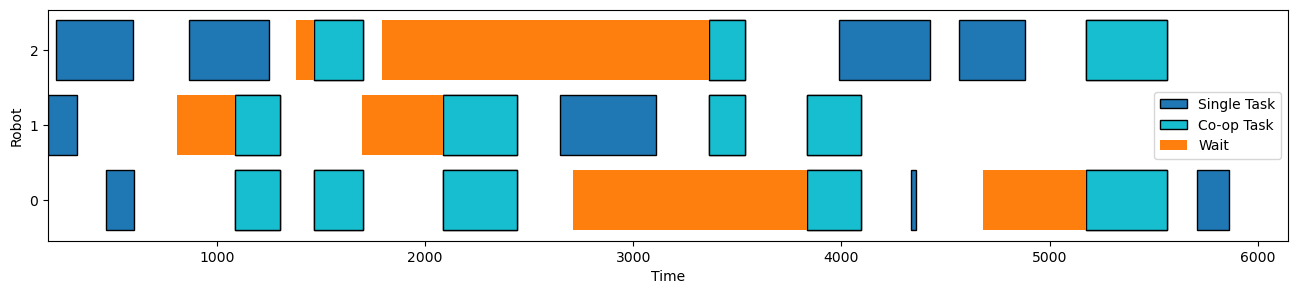

In [21]:
pdpcr_sol.plot_gantt()

#### Plot the gantt chart

In [18]:

import plotly.express as px


In [58]:
tasks = [
    {
    "robot":1,
    "task":3,
    "start":14,
    "duration":15,
    "wait":0
},{
    "robot":2,
    "task":2,
    "start":20,
    "duration":20,
    "wait":0
},{
    "robot":1,
    "task":1,
    "start":60,
    "duration":12,
    "wait":15
},{
    "robot":2,
    "task":1,
    "start":60,
    "duration":12,
    "wait":0
}
]

In [59]:
df_sol = pd.DataFrame(tasks)
df_sol

,robot,task,start,duration,wait
0,1,3,14,15,0
1,2,2,20,20,0
2,1,1,60,12,15
3,2,1,60,12,0


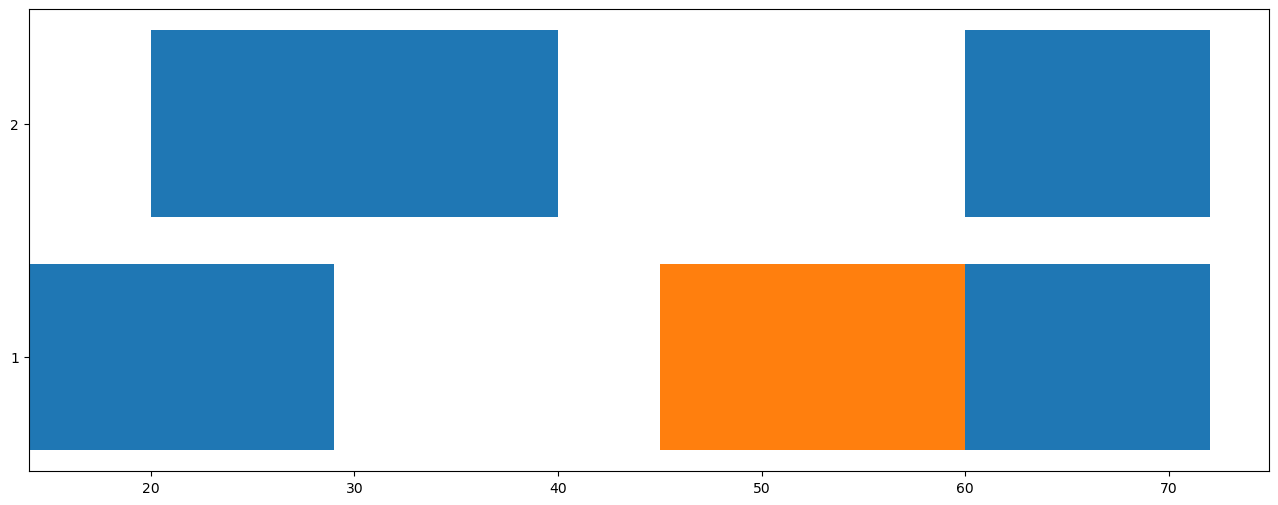

In [60]:
fig,ax = plt.subplots(1, figsize=(16,6))
ax.barh(df_sol.robot.apply(str),df_sol.duration,left = df_sol.start)
ax.barh(df_sol.robot.apply(str),df_sol.wait,left = df_sol.start-df_sol.wait)
plt.show()